# LeafNet — minimal reproduction: stomata detection + pavement cell segmentation on `sample.png`

**Paper:** Li S., Li L., Fan W., Ma S., Zhang C., Kim J.C., Wang K., Russinova E., Zhu Y., Zhou Y. (2022)
*LeafNet: a tool for segmenting and quantifying stomata and pavement cells.* **The Plant Cell** 34(4):1171–1188.
doi:[10.1093/plcell/koac021](https://doi.org/10.1093/plcell/koac021) — PMCID [PMC8972303](https://pmc.ncbi.nlm.nih.gov/articles/PMC8972303/)

**Author code:** `github.com/zhouyulab/leafnet` pinned to commit `6ef237d8fd313e1217f784ba8e45864e85f4b75a` (2021-12-21, latest main).

**Scope (single minimal example):** this notebook runs the **authors' own LeafNet CLI** end-to-end on the repository's documented example input `sample.png` (bright-field *Arabidopsis thaliana* leaf epidermal peel) with the default configuration: `PeeledDenoiser` → `StomaNet` → `LeafSeg`, output mode `ALL`. It produces the preview image (colored cells + stoma ellipses), the annotation image (green walls, blue stomata), and the statistics text file, exactly as the tool's `-m ALL` mode is defined in `leafnet/leafnet_libs/leafnet_exec.py`.

**What this is not:** a benchmark reproduction. The paper's AP/F1 numbers, training experiments, confocal/tobacco/multi-species branches, CNNwall, and the 460-image batch analysis are out of scope. One image is demonstrated.

**JP:** このノートブックは LeafNet 論文の著者提供コード（コミット `6ef237d` 固定）をそのまま使い、リポジトリ同梱のサンプル画像 `sample.png`（明視野シロイヌナズナ表皮剥離像）に対して既定設定（PeeledDenoiser → StomaNet → LeafSeg、出力 ALL）で 1 画像の解析を再現します。ベンチマーク再現ではなく、最小例のデモです。

## 1. Runtime selection — CPU (run all on a **CPU** runtime)

**Runtime → `Edit > Notebook settings > Hardware accelerator: None (CPU)`.**

Why CPU-only: LeafNet's GPU path pins `tensorflow-gpu==1.13.1`, which requires **CUDA 10.0 + cuDNN 7.4** (`requirements_gpu.txt`, README). That stack cannot run on current Colab GPU machines (modern CUDA drivers), while the CPU path of the same pinned version is fully functional. A faithful GPU run would require rewriting the author implementation, which this notebook avoids. CPU inference on this single ~1.9 MB image is fast (tiles of the sliding-window detector + watershed/EDT segmentation).

Expected cost: ~1.5–2 GB of downloads (micromamba + Python 3.7 env + wheels + repo code/weights), total wall time ≈ 10–25 minutes on a standard CPU VM.

**JP:** GPU 版は TensorFlow 1.13.1 + CUDA 10.0（現行 Colab GPU では不可）のため、**CPU ランタイム**を選択してください。CPU 推論は 1 画像なら十分高速です。

## 2. Colab host environment

We first record the Colab VM's own Python/resources. The scientific work will run in an isolated legacy Python 3.7 environment (next section), launched as a subprocess — this keeps the author's pinned stack (`tensorflow==1.13.1` etc.) intact without touching the Colab kernel.

**JP:** まず Colab VM 自体の環境を記録します。本体の解析は次節以降で作る Python 3.7 の隔離環境（サブプロセス）で実行します。

In [ ]:
import os, subprocess, sys
print("Colab kernel python:", sys.version.split()[0])
print(subprocess.run(["nproc"], capture_output=True, text=True).stdout.strip(), "CPU cores")
print(subprocess.run(["free", "-hg"], capture_output=True, text=True).stdout)
print("cwd:", os.getcwd())

Colab kernel python: 3.13.18
2 CPU cores
               total        used        free      shared  buff/cache   available
Mem:            12Gi       900Mi       8.8Gi       2.2Mi       3.3Gi        11Gi
Swap:             0B          0B          0B

cwd: /content


## 3. Legacy Python 3.7 environment (micromamba)

The author code pins **Python 3.6/3.7** (README) and `numpy==1.18` / `np.float` / `selem=` APIs (see `leafnet_libs/cell_divider/LeafSeg/divider.py`), which no longer exist in the Colab kernel's Python. We create an isolated **Python 3.7** env with [micromamba](https://github.com/mamba-org/micromamba-releases) at `/content/leafnet-env`. This runs entirely inside Colab under `/content`; nothing is installed into the notebook kernel.

**JP:** 著者コードは Python 3.6/3.7 固定のため、micromamba で隔離環境 `/content/leafnet-env` を作成します（Colab 内 `/content` にのみ配置）。

In [ ]:
import subprocess, time, os

def run(cmd, cwd=None, timeout=3600):
    print("+", subprocess.list2cmdline(cmd) if isinstance(cmd, list) else cmd, flush=True)
    t0 = time.time()
    p = subprocess.run(cmd, cwd=cwd, shell=isinstance(cmd, str), timeout=timeout,
                       env={**os.environ, "MAMBA_ROOT_PREFIX": "/content/mamba", "MPLBACKEND": "Agg"},  # headless: ignore the Colab kernel's inline backend
                       capture_output=True, text=True)
    if p.stdout: print(p.stdout, flush=True)
    if p.stderr: print(p.stderr, flush=True)
    if p.returncode != 0:
        tail = (p.stdout + p.stderr)[-2000:]
        raise RuntimeError(f"exit code {p.returncode}: {cmd}" + "\n--- output tail ---\n" + (p.stdout + p.stderr)[-2000:])
    print(f"[done in {time.time()-t0:.1f}s]", flush=True)

# micromamba (static binary) -> /content/bin/micromamba
run("wget -qO /content/micromamba.tar.bz2 https://micro.mamba.pm/api/micromamba/linux-64/latest")
run("tar -xjf /content/micromamba.tar.bz2 -C /content bin/micromamba")
# Isolated Python 3.7 env (author pin: README "tested ... with Python 3.6.8"; py3.7 is the newest supported)
run(["/content/bin/micromamba", "create", "-yq", "-p", "/content/leafnet-env",
     "-c", "conda-forge", "python=3.7"], timeout=1800)
run(["/content/leafnet-env/bin/python", "-V"])

+ wget -qO /content/micromamba.tar.bz2 https://micro.mamba.pm/api/micromamba/linux-64/latest


[done in 1.2s]


+ tar -xjf /content/micromamba.tar.bz2 -C /content bin/micromamba


[done in 1.3s]


+ /content/bin/micromamba create -yq -p /content/leafnet-env -c conda-forge python=3.7


[done in 24.5s]


+ /content/leafnet-env/bin/python -V


Python 3.7.12



[done in 0.0s]


## 4. Fetch the pinned author code + example input (partial clone inside Colab)

We clone `zhouyulab/leafnet` with **no blobs** (`--filter=blob:none --no-checkout`), restrict the sparse checkout to `leafnet/` (the package: CLI, models, native libs) and `sample.png` (the documented example input), and check out the exact verified commit `6ef237d8fd313e1217f784ba8e45864e85f4b75a` in detached HEAD. We then assert the HEAD commit and verify `sample.png` byte-for-byte via its **git blob SHA-1** (`346f802b3918343118ca85683c61809f6ccad990`, 1,916,359 bytes, from the GitHub Trees API of that commit).

**JP:** 著者リポジトリを blob なしで部分クローンし、`leafnet/` パッケージと `sample.png` のみをコミット `6ef237d…` で厳密にチェックアウトします。HEAD コミットと `sample.png` の git blob SHA-1（1,916,359 バイト）を検証します。

In [ ]:
import shutil
COMMIT = "6ef237d8fd313e1217f784ba8e45864e85f4b75a"
REPO_DIR = "/content/leafnet"

shutil.rmtree(REPO_DIR, ignore_errors=True)  # idempotent re-runs
run(f"git clone --filter=blob:none --no-checkout https://github.com/zhouyulab/leafnet.git {REPO_DIR}")
run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "leafnet", "sample.png"])
run(["git", "-C", REPO_DIR, "checkout", COMMIT])

head = subprocess.check_output(["git", "-C", REPO_DIR, "rev-parse", "HEAD"]).decode().strip()
assert head == COMMIT, f"checked-out commit mismatch: {head}"
print("HEAD verified:", head)

sample = os.path.join(REPO_DIR, "sample.png")
blob = subprocess.check_output(["git", "-C", REPO_DIR, "hash-object", sample]).decode().strip()
size = os.path.getsize(sample)
assert blob == "346f802b3918343118ca85683c61809f6ccad990" and size == 1916359, (blob, size)
print(f"sample.png verified: {size} bytes, git blob {blob}")

# key bundled artifacts expected from the pinned tree
for rel, expected in [("leafnet/leafnet_libs/stoma_detector/models/StomaNet.model", 10776984),
                      ("leafnet/leafnet_libs/cell_divider/LeafSeg/edt_model.so", 37736),
                      ("leafnet/leafnet_libs/image_denoiser/PeeledDenoiser/gegl_denoise.so", 8200),
                      ("leafnet/leafnet_cli.py", 9580),
                      ("requirements.txt", 137)]:
    p = os.path.join(REPO_DIR, rel)
    assert os.path.getsize(p) == expected, (rel, os.path.getsize(p))
    print(f"  ok {expected:>9} B  {rel}")

+ git clone --filter=blob:none --no-checkout https://github.com/zhouyulab/leafnet.git /content/leafnet


Cloning into '/content/leafnet'...



[done in 0.5s]


+ git -C /content/leafnet sparse-checkout set leafnet sample.png


[done in 0.0s]


+ git -C /content/leafnet checkout 6ef237d8fd313e1217f784ba8e45864e85f4b75a


Note: switching to '6ef237d8fd313e1217f784ba8e45864e85f4b75a'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 6ef237d Updated osx build for PeeledDenoiser.



[done in 1.0s]


HEAD verified: 6ef237d8fd313e1217f784ba8e45864e85f4b75a
sample.png verified: 1916359 bytes, git blob 346f802b3918343118ca85683c61809f6ccad990
  ok  10776984 B  leafnet/leafnet_libs/stoma_detector/models/StomaNet.model
  ok     37736 B  leafnet/leafnet_libs/cell_divider/LeafSeg/edt_model.so
  ok      8200 B  leafnet/leafnet_libs/image_denoiser/PeeledDenoiser/gegl_denoise.so
  ok      9580 B  leafnet/leafnet_cli.py
  ok       137 B  requirements.txt


## 5. Install the author's pinned Python dependencies

The author's `requirements.txt` pins one package per line (shown from the clone in the next cell). Modern pip applies PEP 440 **exact-match** semantics, so most of these pins were never released as exact versions and do not resolve (e.g. `opencv-python==4.1.2`; the 4.1.2-line release is 4.1.2.30). Each pin is therefore resolved to the **latest patch release of the same upstream X.Y line** the authors specified, verified against PyPI metadata on 2026-10-28: `h5py 2.10.0`, `matplotlib 3.1.3`, `numpy 1.18.5`, `opencv-python 4.1.2.30`, `Pillow 7.0.0`, `scikit-image 0.16.2`, `scikit-learn 0.22.2.post1`, `scipy 1.4.1`, and `tensorflow 1.13.1` (the only released 1.13.x — the authors' conda package 1.0.1 ships the same build). Two additional pins keep TF 1.13.1 importable in 2026: `gast==0.2.2` and `protobuf==3.19.6` (newer `gast`/`protobuf` releases break TF 1.13; the authors' 2019-era resolver would have picked these older versions anyway).

**JP:** 著者の `requirements.txt` は pip の完全一致解決では不可（例: `opencv-python==4.1.2` は存在しない）のため、同じ X.Y 系の最新パッチ版へ解決してインストールします。TF 1.13.1 のため `gast==0.2.2` と `protobuf==3.19.6` も固定します。

In [ ]:
# Author's requirements.txt (displayed for provenance):
print(open(os.path.join(REPO_DIR, "requirements.txt")).read())

# PEP 440 exact-match semantics make most of the author's pins unresolvable with pip
# (e.g. "opencv-python==4.1.2" was never released; the 4.1.2-line release is 4.1.2.30).
# Each pin is resolved to the latest patch release of the same upstream X.Y line
# (verified against PyPI metadata 2026-10-28):
PINNED = [
    "h5py==2.10.0", "matplotlib==3.1.3", "numpy==1.18.5", "opencv-python==4.1.2.30",
    "Pillow==7.0.0", "scikit-image==0.16.2", "scikit-learn==0.22.2.post1", "scipy==1.4.1",
    "tensorflow==1.13.1",       # only released 1.13.x (no 1.13.0 on PyPI); same build as conda pkg 1.0.1
    "gast==0.2.2",              # TF 1.13 needs gast 0.2.x; newer gast breaks its imports
    "protobuf==3.19.6",         # protobuf >=3.20 breaks TF 1.13 descriptor loading
]
run(["/content/leafnet-env/bin/pip", "install", "-q", "--no-cache-dir", "--timeout", "60", "--retries", "5"] + PINNED,
    timeout=2400)

h5py==2.10
matplotlib==3.1
numpy==1.18
opencv-python==4.1.2
Pillow==7.0
scikit-image==0.16
scikit-learn==0.22
scipy==1.4
tensorflow==1.13
+ /content/leafnet-env/bin/pip install -q --no-cache-dir --timeout 60 --retries 5 h5py==2.10.0 matplotlib==3.1.3 numpy==1.18.5 opencv-python==4.1.2.30 Pillow==7.0.0 scikit-image==0.16.2 scikit-learn==0.22.2.post1 scipy==1.4.1 tensorflow==1.13.1 gast==0.2.2 protobuf==3.19.6


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 24.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.1/13.1 MB 153.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.1/20.1 MB 189.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.3/28.3 MB 30.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 200.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.5/26.5 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 94.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 26.1/26.1 MB 139.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.6/92.6 MB 140.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 247.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.7/133.7 kB 202.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 177.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 M

[done in 55.9s]


## 6. Verify the legacy stack: TensorFlow, native `.so` libraries, and the StomaNet model

Before running, we check inside the py3.7 env that (a) the pinned packages import, (b) the bundled **ctypes C libraries** (`edt_model.so` for LeafSeg region merging, `gegl_denoise.so` for the PeeledDenoiser) load on the modern glibc, and (c) `tensorflow.keras.models.load_model` opens the bundled `StomaNet.model` (HDF5/Keras format, 10,776,984 B) and reports its input/output tile shapes. The 15-byte `StomaNet.res` metadata (model resolution + DBSCAN profile) is also printed.

**JP:** py3.7 環境内で、依存のインポート、ctypes の C ライブラリ（`edt_model.so` / `gegl_denoise.so`）のロード、`StomaNet.model`（10,776,984 B）のロードを確認します。

In [ ]:
verify = r'''
import ctypes, os, sys
print("python:", sys.version.split()[0])
import numpy as np; print("numpy:", np.__version__)
import tensorflow as tf; print("tensorflow:", tf.__version__)
import cv2; print("opencv:", cv2.__version__)
import skimage, sklearn, scipy, h5py, matplotlib, PIL
print("skimage:", skimage.__version__, "| sklearn:", sklearn.__version__, "| scipy:", scipy.__version__,
      "| h5py:", h5py.__version__, "| Pillow:", PIL.__version__)

LIBS = "/content/leafnet/leafnet/leafnet_libs"
edt = ctypes.cdll.LoadLibrary(os.path.join(LIBS, "cell_divider/LeafSeg/edt_model.so"))
print("edt_model.so loaded, merge_areas:", bool(edt.merge_areas))
gegl = ctypes.cdll.LoadLibrary(os.path.join(LIBS, "image_denoiser/PeeledDenoiser/gegl_denoise.so"))
print("gegl_denoise.so loaded, gegl_denoise:", bool(gegl.gegl_denoise))

from tensorflow.keras.models import load_model
model = load_model(os.path.join(LIBS, "stoma_detector/models/StomaNet.model"))
print("StomaNet.model loaded. input tile:", model.input_shape, "-> output tile:", model.output_shape)
print("StomaNet.res:", open(os.path.join(LIBS, "stoma_detector/models/StomaNet.res")).read().splitlines())
'''
p = subprocess.run(["/content/leafnet-env/bin/python", "-c", verify])
assert p.returncode == 0, "legacy stack verification failed"
# stack verified


## 7. Input preview — `sample.png` (author-provided example)

`sample.png` is the example bright-field leaf epidermal image referenced by the repo README ("Users could take sample.png in this repo for a good example"). Per the paper's Methods, such images are abaxial epidermal peels imaged with a Leica DMi8 at 200x magnification. We display the raw grayscale input before any processing (dimensions printed from the actual file).

**JP:** 著者提供のサンプル入力 `sample.png`（明視野表皮像）を処理前に表示します。論文の Methods によれば、この種の画像は 200 倍明視野での表皮剥離標本です。

sample.png: (1392, 1040) RGBA


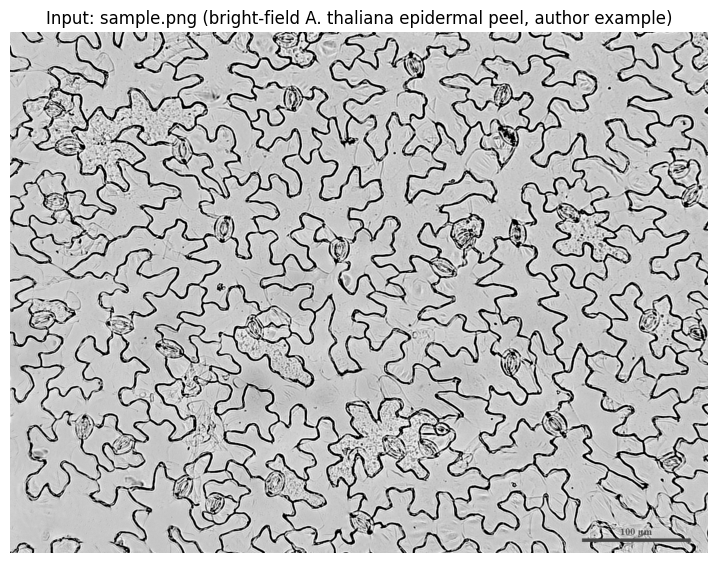

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

img = Image.open(os.path.join(REPO_DIR, "sample.png"))
print("sample.png:", img.size, img.mode)
plt.figure(figsize=(9, 9))
plt.imshow(np.array(img.convert("L")), cmap="gray")
plt.title("Input: sample.png (bright-field A. thaliana epidermal peel, author example)")
plt.axis("off")
plt.show()

## 8. Run LeafNet CLI on `sample.png` (default StomaNet + LeafSeg)

We invoke the authors' own CLI entry point (`python -m leafnet.leafnet_cli`, defined in `leafnet/leafnet_cli.py`) with the configuration documented in the README for exactly this image type. Mapping of the paper's workflow to this call:

| Paper workflow step | LeafNet CLI option | Value |
| --- | --- | --- |
| Denoise bright-field epidermal peel | `--dn` | `PeeledDenoiser` (default) |
| Detect stomata (deep residual net) | `--sd` | `StomaNet` (bundled `StomaNet.model`) |
| Segment pavement cells (region merging) | `--cd` | `LeafSeg` (bundled `edt_model.so`) |
| Bright background / dark walls | `--bg` | `Bright` |
| Input resolution (px/µm) | `--res` | `2.17` (default; training resolution from `StomaNet.res`) |
| Output: preview + annotation + statistics | `-m` | `ALL` |

Outputs land in `/content/leafnet_out/`: `sample.png_graph.png` (preview), `sample.png_anno.png` (annotation), `sample.png_statistic.txt` (measurements, units µm / µm² at 2.17 px/µm).

**JP:** 著者 CLI を README 既定の設定（`StomaNet` + `LeafSeg`、`--res 2.17`、`--bg Bright`、`-m ALL`）で実行します。出力は `/content/leafnet_out/` に保存されます。

In [ ]:
import shutil
cmd = ["/content/leafnet-env/bin/python", "-m", "leafnet.leafnet_cli",
       "-i", os.path.join(REPO_DIR, "sample.png"),
       "-m", "ALL", "-o", "/content/leafnet_out",
       "--res", "2.17", "--bg", "Bright",
       "--dn", "PeeledDenoiser", "--sd", "StomaNet", "--cd", "LeafSeg"]
shutil.rmtree("/content/leafnet_out", ignore_errors=True)  # CLI refuses a non-empty output dir
t0 = time.time()
run(cmd, cwd=REPO_DIR, timeout=3600)
print(f"LeafNet CLI finished in {time.time()-t0:.1f}s")
print(sorted(os.listdir("/content/leafnet_out")))

+ /content/leafnet-env/bin/python -m leafnet.leafnet_cli -i /content/leafnet/sample.png -m ALL -o /content/leafnet_out --res 2.17 --bg Bright --dn PeeledDenoiser --sd StomaNet --cd LeafSeg


/content/leafnet-env/lib/python3.7/site-packages/tensorflow/python/framework/dtypes.py:526: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint8 = np.dtype([("qint8", np.int8, 1)])
/content/leafnet-env/lib/python3.7/site-packages/tensorflow/python/framework/dtypes.py:527: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_quint8 = np.dtype([("quint8", np.uint8, 1)])
/content/leafnet-env/lib/python3.7/site-packages/tensorflow/python/framework/dtypes.py:528: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  _np_qint16 = np.dtype([("qint16", np.int16, 1)])
/content/leafnet-env/lib/python3.7/site-packages/tensorflow/python/framework/dtypes.py:5

[done in 219.3s]


LeafNet CLI finished in 219.3s
['sample.png_anno.png', 'sample.png_graph.png', 'sample.png_statistic.txt']


## 9. Results — preview and annotation images

`sample.png_graph.png` is LeafNet's own preview: each segmented pavement cell is colored, and detected stomata are marked. `sample.png_anno.png` is the GIMP-compatible annotation image (cell walls in green, stomata in blue) defined by `generate_annotation.py`. Both are written by the authors' `leafnet_exec.py` in `-m ALL` mode.

**JP:** LeafNet 自身が生成したプレビュー（細胞の色分け + 気孔の楕円）とアノテーション画像（細胞壁=緑、気孔=青）を表示します。

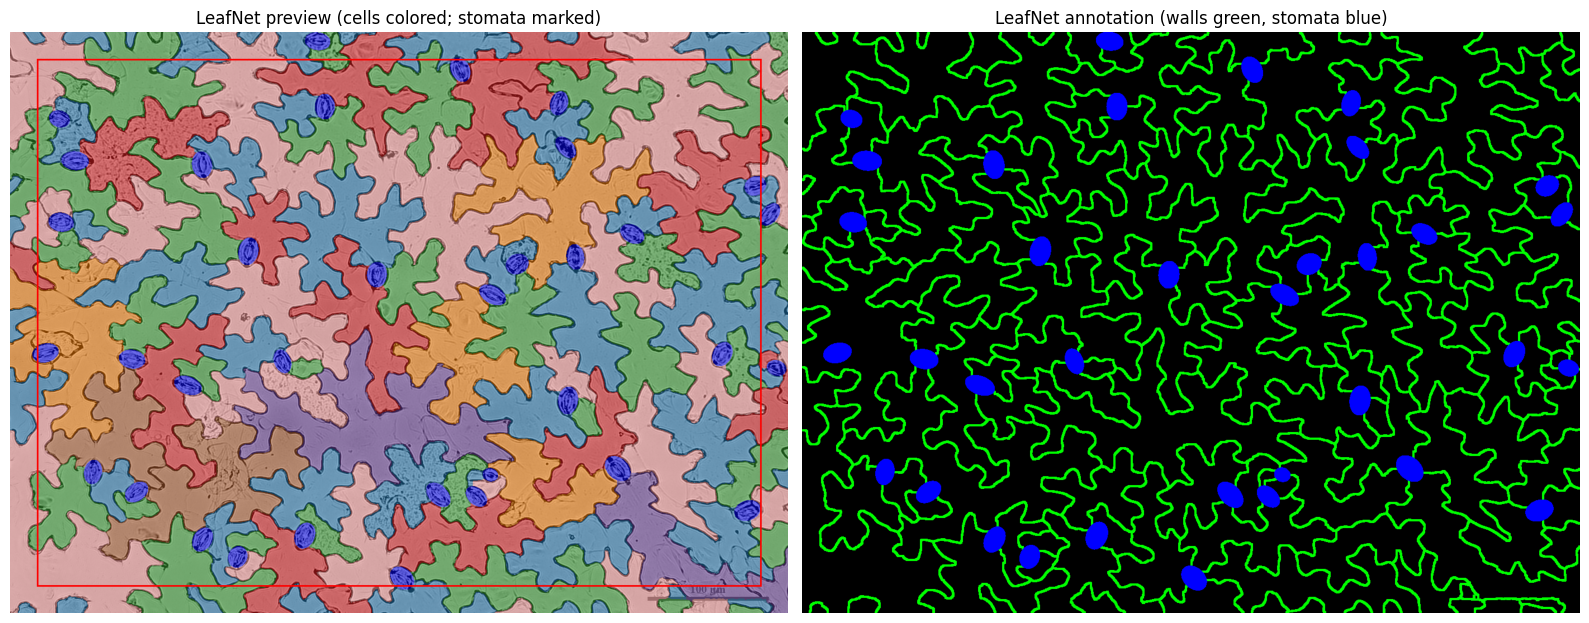

In [ ]:
import matplotlib.image as mpimg

OUT = "/content/leafnet_out"
graph = mpimg.imread(os.path.join(OUT, "sample.png_graph.png"))
anno = mpimg.imread(os.path.join(OUT, "sample.png_anno.png"))
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(graph); axes[0].set_title("LeafNet preview (cells colored; stomata marked)"); axes[0].axis("off")
axes[1].imshow(anno);   axes[1].set_title("LeafNet annotation (walls green, stomata blue)");  axes[1].axis("off")
plt.tight_layout(); plt.show()

## 10. Results — morphological statistics

`sample.png_statistic.txt` (written by `generate_statistics.py`) contains counts and size distributions at the model resolution of 2.17 px/µm. We parse it and summarize: image effective area (border margin 50 px excluded, per the author's code), stoma count, pavement-cell count, mean stoma size/aspect, and mean cell size. Sizes are in µm², lengths in µm.

**JP:** `sample.png_statistic.txt`（2.17 px/µm 時の測定値）を解析し、気孔数・表皮細胞数・平均サイズ等を集計します。単位は µm / µm²。

In [ ]:
import ast, re
import pandas as pd

raw = open(os.path.join(OUT, "sample.png_statistic.txt")).read()
stat = {k: v.strip() for k, v in re.findall(r"^([A-Za-z_]+):(.*)$", raw, re.M)}
print(raw)

stoma_sizes = np.array(ast.literal_eval(stat["stoma_sizes"]), dtype=float)
stoma_aspects = np.array(ast.literal_eval(stat["stoma_aspects"]), dtype=float)
cell_sizes = np.array(ast.literal_eval(stat["cell_sizes"]), dtype=float)
summary = pd.DataFrame([
    ("image_name", stat["image_name"]),
    ("source_image_res (px/um)", float(stat["source_image_res"])),
    ("image_effective_size (um^2)", float(stat["image_effective_size"])),
    ("stoma_count", int(stat["stoma_count"])),
    ("cell_count", float(stat["cell_count"])),
    ("mean_stoma_size (um^2)", stoma_sizes.mean() if stoma_sizes.size else float("nan")),
    ("mean_stoma_aspect (L/W)", stoma_aspects.mean() if stoma_aspects.size else float("nan")),
    ("mean_cell_size (um^2)", cell_sizes.mean() if cell_sizes.size else float("nan")),
], columns=["metric", "value"])
display(summary)
summary.to_csv(os.path.join(OUT, "summary.csv"), index=False)
print("saved:", os.path.join(OUT, "summary.csv"))

image_name:sample.png
source_image_res:2.17
generated_image_res:2.17
image_effective_size:257911.61417740874
stoma_effective_size:8069.825224574742
cell_effective_size:249841.788952834
stoma_count:32
stoma_aspects:[1.375, 1.2777777777777777, 1.2666666666666666, 1.6428571428571428, 1.3333333333333333, 1.4705882352941178, 1.3529411764705883, 1.4375, 1.3888888888888888, 1.4375, 1.1666666666666667, 1.2777777777777777, 1.625, 1.3529411764705883, 1.4666666666666666, 1.411764705882353, 1.625, 1.3888888888888888, 1.368421052631579, 1.375, 1.1666666666666667, 1.4375, 1.5294117647058822, 1.4666666666666666, 1.3333333333333333, 1.3529411764705883, 1.1764705882352942]
stoma_sizes:[234.84053899288733, 276.2044975654982, 190.14077730958206, 214.8257203287208, 288.21338876399807, 283.54326440902594, 260.85980325630385, 245.5151089471095, 300.222279962498, 245.5151089471095, 252.18671516849835, 276.2044975654982, 277.538818809776, 260.85980325630385, 220.16300530583186, 272.2015338326649, 277.53881880

,metric,value
0,image_name,sample.png
1,source_image_res (px/um),2.17
2,image_effective_size (um^2),257911.614177
3,stoma_count,32
4,cell_count,77.5
5,mean_stoma_size (um^2),255.176583
6,mean_stoma_aspect (L/W),1.389043
7,mean_cell_size (um^2),2924.061502


saved: /content/leafnet_out/summary.csv


## 11. Size distributions (additional visualization created for this notebook)

Histograms of the stoma and pavement-cell size distributions reported in the statistics file — this graph is **not** a paper figure; it is plotted here from the actual `sample.png_statistic.txt` output to make the measurement distributions inspectable.

**JP:** 統計ファイルの実測値から気孔・表皮細胞サイズの分布を描画します（論文の図ではなく本ノートブック独自の追加可視化です）。

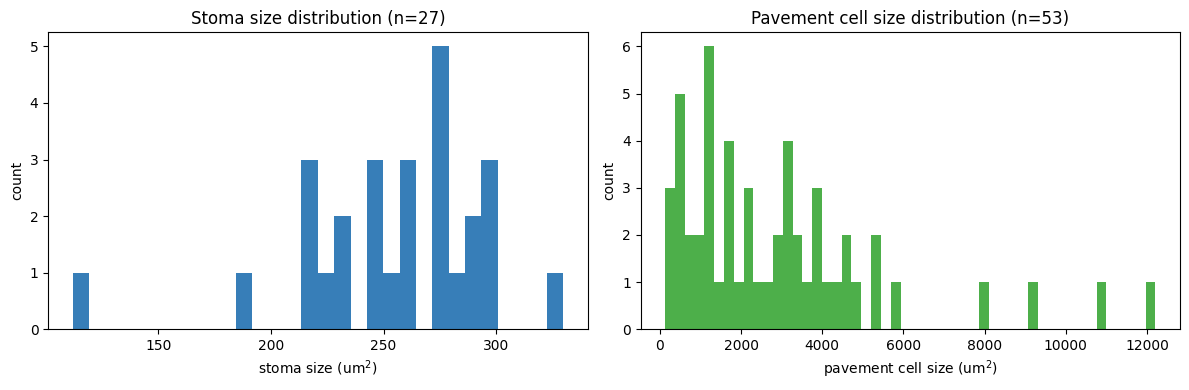

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(stoma_sizes, bins=30, color="#377eb8")
axes[0].set_xlabel("stoma size (um$^2$)"); axes[0].set_ylabel("count")
axes[0].set_title(f"Stoma size distribution (n={stoma_sizes.size})")
axes[1].hist(cell_sizes, bins=50, color="#4daf4a")
axes[1].set_xlabel("pavement cell size (um$^2$)"); axes[1].set_ylabel("count")
axes[1].set_title(f"Pavement cell size distribution (n={cell_sizes.size})")
plt.tight_layout(); plt.show()

## 12. Interpretation, limitations, and references

**What was reproduced:** the authors' LeafNet CLI (`-m ALL`) on the bundled example input with the default `StomaNet` + `LeafSeg` pipeline, producing the same three artifacts the tool documents (preview, annotation, statistics). Counts and distributions above are the actual run outputs on this Colab VM, measured at the model's 2.17 px/µm resolution.

**Limitations (single-example demonstration):** no comparison to the paper's reported accuracy (AP 98.1% stoma detection / AP 89.1% pavement-cell segmentation on held-out test sets) was attempted; one image cannot validate dataset-level performance. The legacy stack (Python 3.7, TensorFlow 1.13.1 CPU) is exactly the author's pinned environment, executed via subprocess. Training, other models (`StomaNetConfocal`, `StomaNetUniversal`), `CNNwall`, and batch modes are out of scope. The repo has no LICENSE file (conda metadata states MIT) — reuse terms should be confirmed before redistribution.

**References:**
- Li S. et al. (2022) The Plant Cell 34(4):1171–1188, doi:10.1093/plcell/koac021 (PMCID PMC8972303).
- Code: https://github.com/zhouyulab/leafnet @ `6ef237d8fd313e1217f784ba8e45864e85f4b75a`.
- Tool website: https://leafnet.whu.edu.cn/

**JP:** 本ノートブックは著者 CLI の最小例（1 画像）の実行再現であり、論文の精度評価（AP 等）・学習・他モデルの検証は含みません。測定値はこの Colab VM 上での実際の出力です。